# Phase 1: Supervised Learning
**SWE485 – Team Project | SW485-Project-Group2**
**Project:** Predicting Data Scientist Job Change: An Executive Decision-Support System for HR Retention Planning

| Section | Owner |
|---------|-------|
| 1. Model Selection Rationale | Munira (Model 1), Ghala (Model 2) |
| 2. Implementation & Training Code | Munira (Model 1), Ghala (Model 2) |
| 3. Hyperparameter Tuning Process & Results | Munira (Model 1), Ghala (Model 2) |
| 4. Evaluation Metrics & Visualizations | Munira, Ghala (own model), Fatimah (shared evaluation) |
| 5. Model Comparison & Analysis | Fatimah |
| 6. Conclusion: Best Model Selection & Reasoning | Fatimah |
| 7. Next Steps for Phase 2 Integration | Fatimah |

**Shared rules (so the two models can be compared fairly):** the same train/test split, `random_state=42`, and the same stratified 5-fold cross-validation for both models. The target is imbalanced (about 25% positive), so do not judge a model by accuracy alone.

## Setup
Shared imports, data loading, train/test split, and cross-validation settings, defined once so both models are trained and evaluated on exactly the same data.

In [2]:
# Shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42

# Load the preprocessed data (produced in Phase1_Data_Exploration.ipynb)
df = pd.read_csv("Dataset/preprocessed_data.csv")
X = df.drop(columns=["target"])
y = df["target"]

# Same stratified train/test split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Same 5-fold stratified cross-validation for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Positive rate (train):", round(y_train.mean(), 4), "| (test):", round(y_test.mean(), 4))

Matplotlib is building the font cache; this may take a moment.


Train: (14916, 32) | Test: (3729, 32)
Positive rate (train): 0.2464 | (test): 0.2464


In [3]:
# Shared helper: the same metrics for every model (call it with a fitted model)
def evaluate_model(name, model, X_test, y_test):
    """Return Accuracy, Precision, Recall, F1 and ROC-AUC on the test set."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

## 1. Model Selection Rationale
*Choose at least 2 different supervised algorithms. Justify each choice based on (i) dataset characteristics (size, feature types, linearity), (ii) problem type (binary classification), and (iii) the model's strengths and weaknesses for this problem, including interpretability for leadership.*

### 1.1 Model 1: _<algorithm name>_ (Munira)
*To be added.*

### 1.2 Model 2: _<algorithm name>_ (Ghala)

Algorithm Name: Extreme Gradient Boosting (XGBoost)

Rationale & Justification:

Dataset Characteristics: The HR Analytics dataset contains a mixture of tabular numerical and categorical features with potential non-linear relationships and interactions. XGBoost excels at handling complex tabular structures without requiring assumptions of linearity.

Problem Type (Binary Classification): XGBoost utilizes gradient-boosted decision trees optimized for binary classification tasks, making it highly effective at handling imbalanced target distributions (predicting employee attrition/job change).

Strengths & Weaknesses:

Strengths: Exceptional predictive accuracy, high efficiency, native handling of missing patterns, and built-in regularization to prevent overfitting.

Weaknesses: Slightly higher computational complexity during tuning compared to traditional linear models.

Interpretability for Leadership: While complex, XGBoost provides clear feature importance metrics (e.g., gain, cover, frequency) and tree visualization capabilities, allowing leadership to understand which specific factors (such as experience or training hours) drive employee retention decisions.

## 2. Implementation & Training Code
*Well-structured, commented code.*

### 2.1 Model 1 (Munira)

In [ ]:
# Model 1: build and train (Munira)

### 2.2 Model 2 (Ghala)

In [4]:
import xgboost as xgb

# 1. Initialize the default XGBoost Classifier with the shared RANDOM_STATE
xgb_default = xgb.XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    use_label_encoder=False
)

# 2. Train the baseline model on the training set
xgb_default.fit(X_train, y_train)

# 3. Evaluate the baseline model using the shared team function
xgb_default_results = evaluate_model("XGBoost (Baseline)", xgb_default, X_test, y_test)

# Display baseline results
print("=== Baseline XGBoost Results ===")
for metric, score in xgb_default_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

C:\Users\ghala\AppData\Roaming\uv\python\cpython-3.14-windows-x86_64-none\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:38:54] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== Baseline XGBoost Results ===
Accuracy: 0.7922
Precision: 0.5878
Recall: 0.5245
F1: 0.5543
ROC-AUC: 0.8052


## 3. Hyperparameter Tuning Process & Results
*For each model: the parameters tried, how they were searched (e.g. grid search with the shared `cv`), and the best values found.*

### 3.1 Model 1 (Munira)

In [ ]:
# Model 1: hyperparameter tuning (Munira)

### 3.2 Model 2 (Ghala)

In [5]:
# 1. Define the hyperparameter search grid
param_grid = {
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 150],
    'subsample': [0.8, 1.0]
}

# 2. Setup GridSearchCV using the shared Stratified 5-Fold CV (`cv`)
grid_search_xgb = GridSearchCV(
    estimator=xgb.XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', use_label_encoder=False),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# 3. Execute Grid Search on training data
grid_search_xgb.fit(X_train, y_train)

# 4. Extract best estimator and parameters
best_xgb_model = grid_search_xgb.best_estimator_
print("=== Best Hyperparameters Found ===")
print(grid_search_xgb.best_params_)

# 5. Evaluate the tuned model
tuned_xgb_results = evaluate_model("XGBoost (Tuned)", best_xgb_model, X_test, y_test)
print("\n=== Tuned XGBoost Results ===")
for metric, score in tuned_xgb_results.items():
    if metric != "Model":
        print(f"{metric}: {score:.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits
=== Best Hyperparameters Found ===
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50, 'subsample': 1.0}

=== Tuned XGBoost Results ===
Accuracy: 0.7986
Precision: 0.5959
Recall: 0.5680
F1: 0.5816
ROC-AUC: 0.8159


C:\Users\ghala\AppData\Roaming\uv\python\cpython-3.14-windows-x86_64-none\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:47:36] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## 4. Evaluation Metrics & Visualizations
*Metrics: Accuracy, Precision, Recall, F1-Score, Confusion Matrix, ROC-AUC. Apply 5-fold cross-validation. Visualizations: confusion matrix heatmap, ROC curves, and feature importance (for tree-based models). Add a short interpretation under every chart or table.*

### 4.1 Model 1 (Munira)

In [ ]:
# Model 1: test-set metrics, 5-fold CV, confusion matrix heatmap, ROC curve, feature importance (Munira)

### 4.2 Model 2 (Ghala)

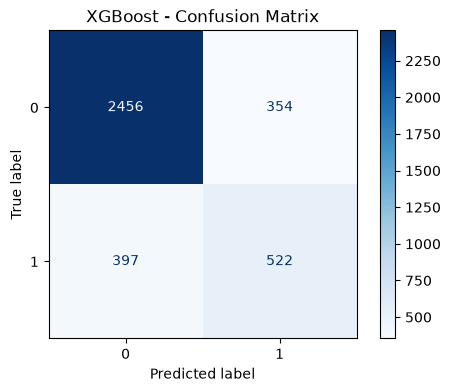

In [6]:
# 1. Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_estimator(best_xgb_model, X_test, y_test, cmap="Blues", ax=ax)
plt.title("XGBoost - Confusion Matrix")
plt.grid(False)
plt.show()

The confusion matrix shows the distribution of true positives, true negatives, false positives, and false negatives. Given that the dataset is imbalanced (~25% positive rate), our primary focus is minimizing false negatives to ensure potential employee attrition is identified reliably.

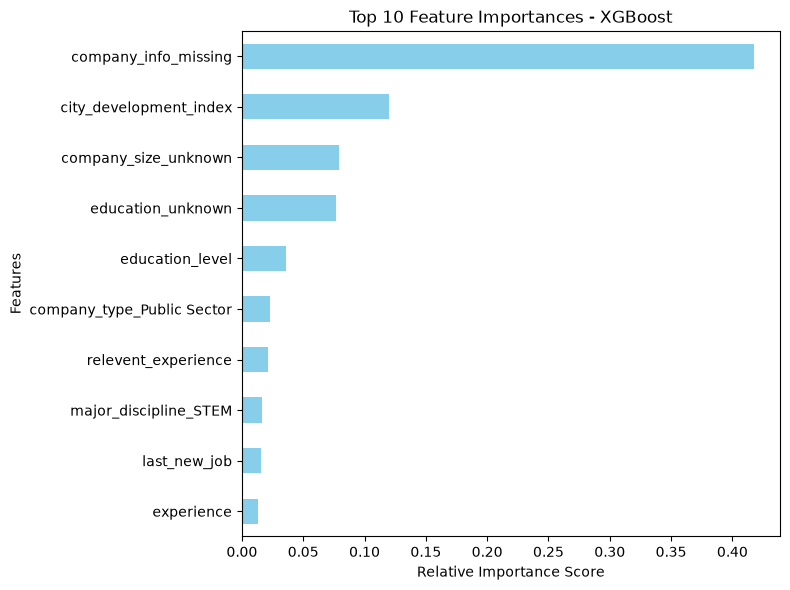

In [7]:
# 2. Feature Importance Plot
feature_importances = pd.Series(best_xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
feature_importances.tail(10).plot(kind='barh', color='skyblue')
plt.title("Top 10 Feature Importances - XGBoost")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

The feature importance chart displays the top factors driving the model's predictions. Features with higher relative importance scores have the strongest influence on determining whether an employee is likely to look for a job change.

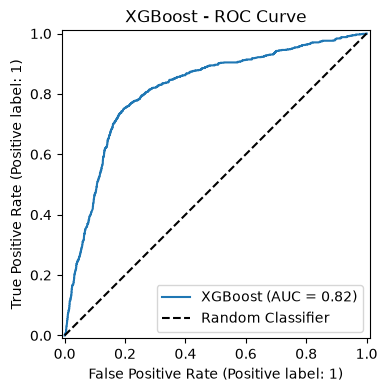

In [8]:
# 3. ROC Curve Plot
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 4))
RocCurveDisplay.from_estimator(best_xgb_model, X_test, y_test, ax=ax, name="XGBoost")
plt.title("XGBoost - ROC Curve")
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.legend()
plt.show()

The Receiver Operating Characteristic (ROC) curve evaluates the trade-off between the True Positive Rate and False Positive Rate across various threshold levels. An Area Under the Curve (ROC-AUC) score significantly above 0.50 demonstrates strong discrimination capability between positive and negative classes.

### 4.3 Side-by-Side Metrics and ROC Curves (Fatimah)
*Put both models' metrics in one table and both ROC curves on one plot.*

In [ ]:
# Combined metrics table and ROC curves (Fatimah)

## 5. Model Comparison & Analysis
*Owner: Fatimah.*
- Which model performed best, and why?
- Analyze misclassifications: patterns and challenging categories.
- Discuss trade-offs: accuracy vs. interpretability vs. computational cost.

## 6. Conclusion: Best Model Selection & Reasoning
*Owner: Fatimah – which model will be used in the final system and why.*

## 7. Next Steps for Phase 2 Integration
*Owner: Fatimah – how the chosen model will feed Phase 2 (clustering, Generative AI executive briefings, and the dashboard).*